In [1]:
import pandas as pd
from time import time

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, RobustScaler, QuantileTransformer, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from xgboost import XGBClassifier

from sklearn.ensemble import HistGradientBoostingClassifier, ExtraTreesClassifier
from sklearn.neural_network import MLPClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

import matplotlib.pyplot as plt
from feature_engine.outliers import Winsorizer
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import cross_val_score

RT = 42
RANDOM_STATE = 42

In [2]:
# 0. load data

X_test = pd.read_csv("/Users/fangsiyu/Desktop/SDU-2026-fall-code/AML/kaggle/X_test.csv")

X_train = pd.read_csv("/Users/fangsiyu/Desktop/SDU-2026-fall-code/AML/kaggle/X_train.csv")
y_train = pd.read_csv("/Users/fangsiyu/Desktop/SDU-2026-fall-code/AML/kaggle/y_train.csv")
# ==========================================================================================

X_test['Gender'] = X_test['Gender'].map({'Female': 0, 'Male': 1})

X_train['Gender'] = X_train['Gender'].map({'Female': 0, 'Male': 1})
y_train['Diabetes'] = y_train['Diabetes'].map({'No': 0, 'Yes': 1})
# ==========================================================================================

X_train = X_train.set_index('ID')
X_test = X_test.set_index('ID')
y_train = y_train.set_index('ID')['Diabetes']

assert X_train.index.equals(y_train.index)

In [3]:
# 1. train_test_split

X_t, X_val, y_t, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.001,
    random_state=RANDOM_STATE,
    stratify=y_train
)
print(f"X_t, y_t, {len(X_t), len(y_t)} \nX_val, y_val {len(X_val), len(y_val)}")
print(f"Length of X_test {len(X_test)}")

X_t, y_t, (52965, 52965) 
X_val, y_val (54, 54)
Length of X_test 17673


In [4]:
for col in X_train.columns:
    print(col, X_train[col].value_counts().to_dict())

HighBP {1.0: 29816, 0.0: 23203}
HighChol {1.0: 27798, 0.0: 25221}
CholCheck {1.0: 51722, 0.0: 1297}
BMI {27.0: 4759, 26.0: 3770, 28.0: 3449, 24.0: 3258, 29.0: 3231, 30.0: 3205, 25.0: 2942, 31.0: 2817, 32.0: 2577, 23.0: 2523, 33.0: 2329, 22.0: 2103, 34.0: 1933, 21.0: 1565, 35.0: 1546, 36.0: 1353, 37.0: 1219, 38.0: 1021, 20.0: 971, 39.0: 909, 40.0: 700, 19.0: 546, 41.0: 527, 43.0: 508, 42.0: 504, 44.0: 354, 18.0: 280, 45.0: 279, 46.0: 253, 47.0: 208, 48.0: 156, 49.0: 153, 50.0: 146, 17.0: 127, 51.0: 92, 52.0: 87, 53.0: 75, 55.0: 71, 16.0: 50, 56.0: 44, 54.0: 38, 58.0: 33, 57.0: 31, 15.0: 25, 59.0: 24, 60.0: 19, 63.0: 14, 87.0: 13, 77.0: 12, 79.0: 11, 84.0: 11, 61.0: 11, 62.0: 11, 81.0: 10, 14.0: 10, 75.0: 10, 71.0: 9, 82.0: 9, 73.0: 8, 64.0: 8, 65.0: 7, 92.0: 7, 70.0: 7, 66.0: 7, 67.0: 7, 68.0: 7, 72.0: 6, 13.0: 4, 89.0: 3, 74.0: 2, 85.0: 1, 98.0: 1, 80.0: 1, 95.0: 1, 78.0: 1}
Smoker {0.0: 27933, 1.0: 25086}
Stroke {0.0: 49698, 1.0: 3321}
HeartDiseaseorAttack {0.0: 45156, 1.0: 7863}
Phys

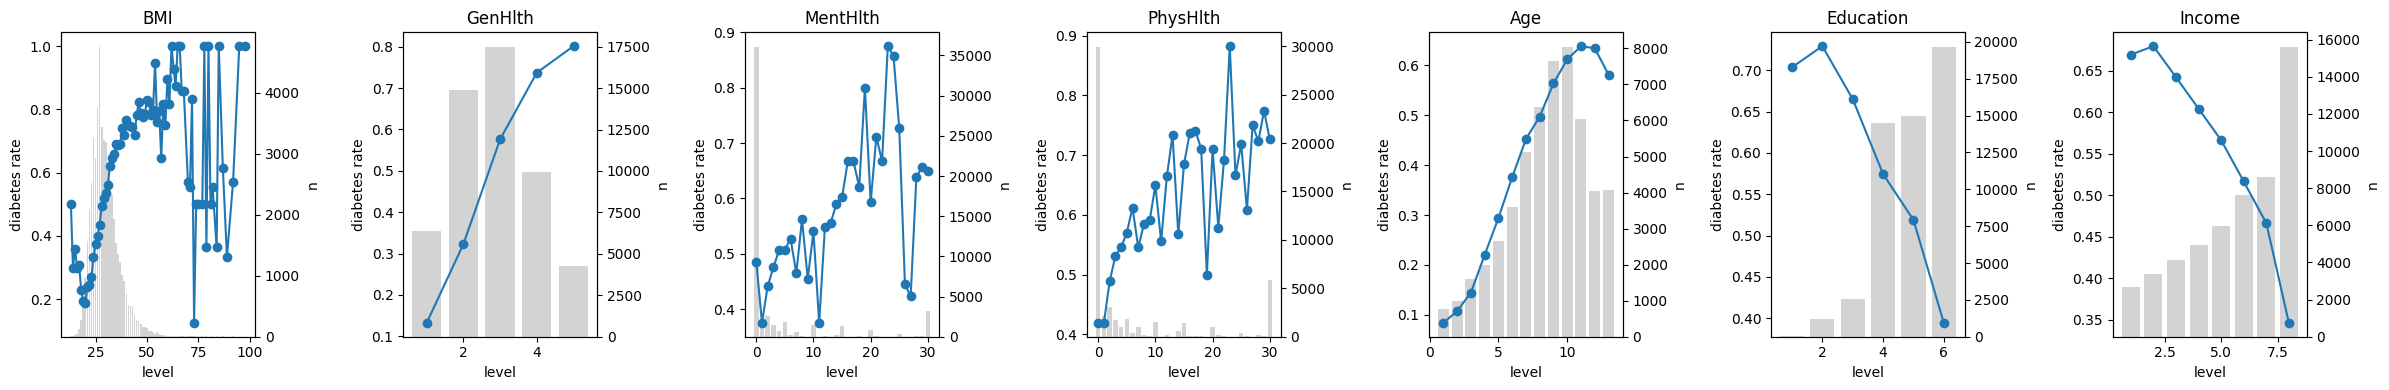

In [5]:
cols = ['BMI','GenHlth', 'MentHlth','PhysHlth','Age', 'Education', 'Income']

def make_plots(cols, df):
    for col in cols:
        table = (
            pd.DataFrame({'level': df[col], 'diabetes': y_t})
            .groupby('level')['diabetes']
            .agg(rate='mean', n='size')
        )
        table['diff'] = table['rate'].diff()

    fig, axes = plt.subplots(1, len(cols), figsize=(24, 4))

    for ax, col in zip(axes, cols):
        g = y_t.groupby(df[col])
        rate = g.mean()   # 每個值的糖尿病比例
        n = g.size()      # 每個值有幾個人

        ax2 = ax.twinx()
        ax2.bar(n.index, n.values, color='lightgray', width=0.8)
        ax2.set_ylabel('n')

        ax.plot(rate.index, rate.values, marker='o', color='C0')
        ax.set_title(col)
        ax.set_xlabel('level')
        ax.set_ylabel('diabetes rate')

        ax.set_zorder(ax2.get_zorder() + 1)
        ax.patch.set_visible(False)

    plt.tight_layout()
    plt.show()

make_plots(cols, X_t)

In [ ]:
# preprocessor
from feature_engine.outliers import Winsorizer

BINARY_COLS = [
    'HighBP', 'HighChol', 'CholCheck', 'Smoker', 'Stroke', 'HeartDiseaseorAttack',
    'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare',
    'NoDocbcCost', 'DiffWalk', 'Gender',
]
NUMERIC_COLS = ['MentHlth', 'PhysHlth', 'Education', 'Income']
ONEHOT_COLS = ['GenHlth', 'Age']

RISK_COLS = ['HighBP', 'HighChol', 'Stroke', 'HeartDiseaseorAttack', 'DiffWalk']


def make_preprocessor():
    return ColumnTransformer(
        [
            ("bmi", Pipeline([
                ("clip", Winsorizer(capping_method="quantiles", tail="right", fold=0.01)),
                ("scale", StandardScaler()),
            ]), ['BMI']),
            ("num", StandardScaler(), NUMERIC_COLS),
            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ONEHOT_COLS),
        ],
        remainder="passthrough",
    )


SCALER_OPTIONS = [
    StandardScaler(),
    MinMaxScaler(),
    QuantileTransformer(output_distribution="normal", random_state=RT),
]


def scaler_name(s):
    return "-" if s is None else type(s).__name__

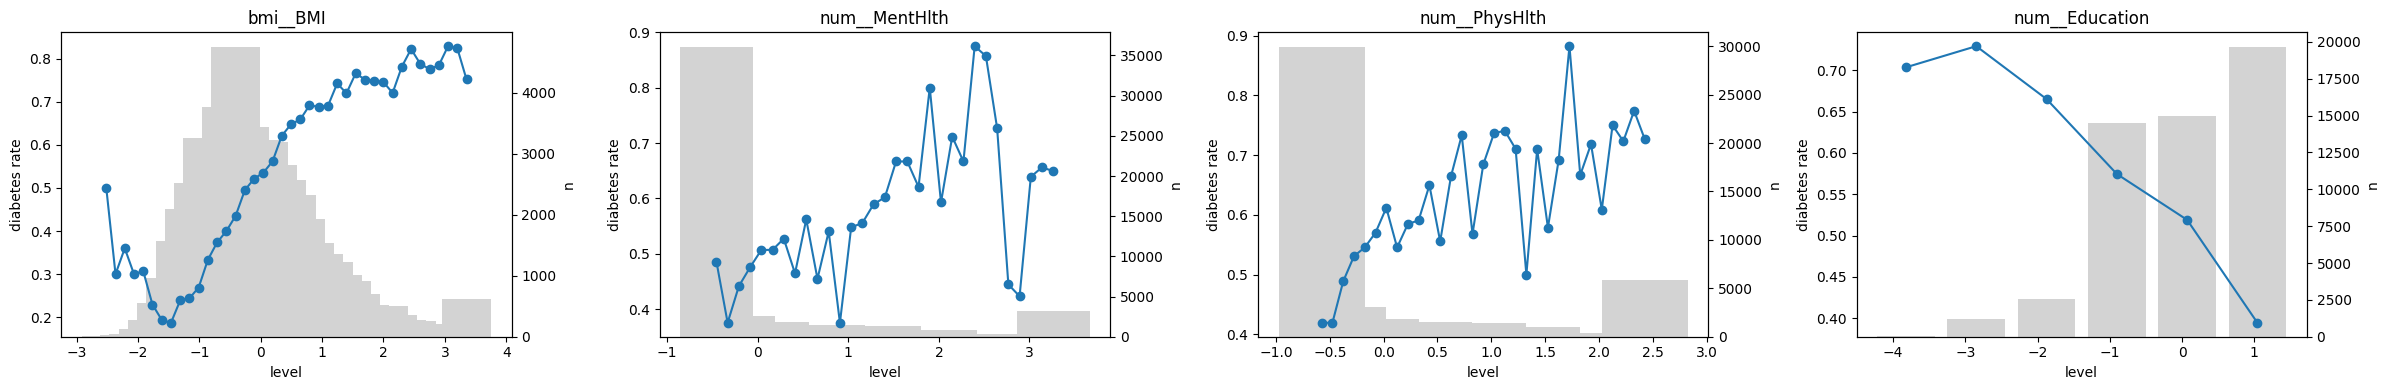

In [8]:
prep = make_preprocessor().fit(X_t)
Xt_prep = pd.DataFrame(prep.transform(X_t),
                       columns=prep.get_feature_names_out(), index=X_t.index)

new_cols = ['bmi__BMI', 'num__MentHlth','num__PhysHlth', 'num__Education']

make_plots(new_cols, Xt_prep)

In [36]:
# X_t2, X_val2 = add_features(X_t), add_features(X_val)
# BASE_NUM = ['MentHlth', 'PhysHlth', 'Education', 'Income']

# feat_rows = []
# for mode, X_tr, X_v, num_cols in [
#     ("基準",        X_t,  X_val,  BASE_NUM),
#     ("+ RiskCount", X_t2, X_val2, BASE_NUM + ['RiskCount']),
# ]:
#     NUMERIC_COLS = num_cols   # RiskCount 當數字、做 scale

#     for name, clf in models.items():
#         model = Pipeline([("prep", make_preprocessor()), ("clf", clone(clf))])

#         cv_scores = cross_val_score(model, X_tr, y_t, cv=cv, scoring="accuracy", n_jobs=-1)
#         val_score = model.fit(X_tr, y_t).score(X_v, y_val)

#         feat_rows.append({"設定": mode, "模型": name,
#                           "CV 平均": cv_scores.mean(), "CV 標準差": cv_scores.std(), "Val": val_score})

# NUMERIC_COLS = BASE_NUM   # 改回正式設定

# pd.DataFrame(feat_rows).sort_values(["模型", "Val"], ascending=[True, False]).round(4)

,設定,模型,CV 平均,CV 標準差,Val
0,基準,LR,0.7539,0.0037,0.7526
2,+ RiskCount,LR,0.7537,0.0041,0.7525
3,+ RiskCount,XGB,0.7554,0.0033,0.7565
1,基準,XGB,0.7563,0.0035,0.7562


In [ ]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.kernel_approximation import Nystroem
from sklearn.preprocessing import PolynomialFeatures

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RT)
def with_prep(*steps):
    return Pipeline([("prep", make_preprocessor()), *steps])

search_space = {
    # "Logistic Regression": (
    #     with_prep(("clf", LogisticRegression(solver="liblinear", max_iter=5000, random_state=RT))),
    #     {"prep__num": SCALER_OPTIONS,
    #      "clf__l1_ratio": [0, 1],
    #      "clf__C": [0.01, 0.03, 0.1, 0.3, 1]},
    # ),
    # "LR + Interactions": (
    #     with_prep(("poly", PolynomialFeatures(degree=2, interaction_only=True, include_bias=False)),
    #               ("clf", LogisticRegression(max_iter=5000, random_state=RT))),
    #     {"prep__num": [StandardScaler()],
    #      "clf__C": [0.01, 0.1]},
    # ),
    # "LDA": (
    #     with_prep(("clf", LinearDiscriminantAnalysis(solver="lsqr"))),
    #     {"prep__num": SCALER_OPTIONS,
    #      "clf__shrinkage": [None, "auto"]},
    # ),
    # "Kernel SVM (Nystroem)": (
    #     with_prep(("kernel", Nystroem(kernel="rbf", n_components=500, random_state=RT)),
    #               ("clf", LogisticRegression(max_iter=5000, random_state=RT))),
    #     {"prep__num": [StandardScaler()],
    #      "kernel__gamma": [0.02, 0.05, 0.1],
    #      "clf__C": [0.3, 1, 3]},
    # ),
    # "KNN": (
    #     with_prep(("clf", KNeighborsClassifier())),
    #     {"prep__num": SCALER_OPTIONS,
    #      "clf__n_neighbors": [50, 75, 100],
    #      "clf__p": [1, 2]},
    # ),

    # "Random Forest": (RandomForestClassifier(n_estimators=500, max_depth=15, min_samples_leaf=5,
    #                                          max_features="sqrt", random_state=RT, n_jobs=1), {}),
    # "Extra Trees": (ExtraTreesClassifier(n_estimators=500, max_depth=15, min_samples_leaf=10,
    #                                      max_features=0.5, random_state=RT, n_jobs=1), {}),
    # "Decision Tree": (DecisionTreeClassifier(max_depth=8, min_samples_leaf=20, random_state=RT), {}),
    # "CatBoost": (CatBoostClassifier(depth=6, iterations=600, l2_leaf_reg=10, learning_rate=0.03,
    #                                 random_seed=RT, verbose=0, thread_count=1), {}),
    # "HistGradientBoosting": (HistGradientBoostingClassifier(max_iter=200, max_leaf_nodes=15,
    #                                                         min_samples_leaf=50, random_state=RT), {}),


    "Gradient Boosting": (
        GradientBoostingClassifier(random_state=RT),
        {"learning_rate": [0.03, 0.05, 0.1],
         "max_depth": [3, 4, 5],
         "min_samples_leaf": [20, 50, 100],
         "n_estimators": [200, 400, 600],
         "subsample": [0.8, 1.0]},
    ),
    "Random Forest": (
        RandomForestClassifier(random_state=RT, n_jobs=1),
        {"n_estimators": [300, 500],
         "max_depth": [10, 15, 20, None],
         "min_samples_leaf": [1, 5, 10, 20],
         "max_features": ["sqrt", 0.3, 0.5]},
    ),
    "HistGradientBoosting": (
        HistGradientBoostingClassifier(random_state=RT),
        {"learning_rate": [0.03, 0.05, 0.1],
         "max_iter": [200, 400],
         "max_leaf_nodes": [7, 15, 31],
         "min_samples_leaf": [20, 50, 100],
         "l2_regularization": [0, 0.3, 1]},
    ),
    # "LightGBM": (LGBMClassifier(n_estimators=300, num_leaves=7, colsample_bytree=0.6, subsample=0.7,
    #                             subsample_freq=1, reg_lambda=1, random_state=RT, n_jobs=1, verbose=-1), {}),

    "Dummy": (DummyClassifier(strategy="most_frequent"), {}),
}

In [ ]:
from sklearn.model_selection import RandomizedSearchCV, ParameterGrid

N_ITER = 60   # ← 組合數超過這個值，就改成隨機抽這麼多組

rows, best_models, searches = [], {}, {}

for name, (model, grid) in search_space.items():
    t0 = time()
    n_combos = len(ParameterGrid(grid))
    common = dict(cv=cv, refit="accuracy", n_jobs=-1,
                  scoring={"accuracy": "accuracy", "f1": "f1", "roc_auc": "roc_auc"})
    if n_combos > N_ITER:                                                      # ←
        search = RandomizedSearchCV(model, grid, n_iter=N_ITER, random_state=RT, **common)
    else:
        search = GridSearchCV(model, grid, **common)
    search.fit(X_t, y_t)

    searches[name] = search
    best_models[name] = search.best_estimator_
    i, cvr = search.best_index_, search.cv_results_
    proba = search.predict_proba(X_val)[:, 1]
    pred = search.predict(X_val)

    rows.append({
        "Model": name,
        "Scaler": scaler_name(search.best_params_.get("prep__num")),
        "Tried": f"{min(n_combos, N_ITER)}/{n_combos}",
        "CV Acc": cvr["mean_test_accuracy"][i],
        "CV Acc std": cvr["std_test_accuracy"][i],
        "CV F1": cvr["mean_test_f1"][i],
        "CV AUC": cvr["mean_test_roc_auc"][i],
        "Val Acc": accuracy_score(y_val, pred),
        "Val F1": f1_score(y_val, pred),
        "Val AUC": roc_auc_score(y_val, proba),
        "Time (s)": round(time() - t0),
    })
    print(f"{name} done, {rows[-1]['Time (s)']} sec")

grid_results = (pd.DataFrame(rows)
                .sort_values("CV Acc", ascending=False)
                .reset_index(drop=True))
grid_results.round(3)

Gradient Boosting done, 398 sec


/Users/fangsiyu/dev-env/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Random Forest done, 365 sec


/Users/fangsiyu/dev-env/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


HistGradientBoosting done, 42 sec
Dummy done, 0 sec


,Model,Scaler,Tried,CV Acc,CV Acc std,CV F1,CV AUC,Val Acc,Val F1,Val AUC,Time (s)
0,Gradient Boosting,-,60/162,0.758,0.004,0.768,0.835,0.741,0.741,0.860,398
1,HistGradientBoosting,-,60/162,0.757,0.004,0.766,0.834,0.759,0.755,0.861,42
2,Random Forest,-,60/96,0.755,0.004,0.765,0.832,0.778,0.769,0.877,365
3,Dummy,-,1/1,0.500,0.000,0.267,0.500,0.500,0.667,0.500,0


In [11]:
# therahold testing

from sklearn.model_selection import cross_val_predict
from sklearn.base import clone
import numpy as np
proba_oof = cross_val_predict(clone(best_models["CatBoost"]), X_t, y_t,
                              cv=cv, method="predict_proba", n_jobs=-1)[:, 1]

thr = np.arange(0.30, 0.71, 0.02)
thr_table = pd.DataFrame({
    "門檻": thr,
    "Accuracy": [accuracy_score(y_t, proba_oof >= t) for t in thr],
    "F1": [f1_score(y_t, proba_oof >= t) for t in thr],
})
thr_table.round(4)

,門檻,Accuracy,F1
0,0.30,0.7299,0.7743
1,0.32,0.7361,0.7768
2,0.34,0.7401,0.7775
3,0.36,0.7448,0.7785
4,0.38,0.7482,0.7787
5,0.40,0.7513,0.7787
6,0.42,0.7532,0.7773
7,0.44,0.7557,0.7764
8,0.46,0.7565,0.7737
9,0.48,0.7580,0.7714


In [ ]:
# best_name = grid_results.loc[0, "Model"]
final_model = best_models['Gradient Boosting']

final_model.fit(X_train, y_train)
y_pred_test = final_model.predict(X_test)

submission = pd.DataFrame({"ID": X_test.index, "Diabetes": y_pred_test})
submission['Diabetes'] = submission['Diabetes'].map({0: 'No', 1: 'Yes'})


submission.to_csv("submission_v18_GB.csv", index=False)

# print(best_name)
# print(submission.head())

In [17]:
best_models['Gradient Boosting']

,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.05
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",200
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",0.8
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",50
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (

---
## Ensembles

In [17]:
import joblib
from time import time
from sklearn.base import clone
from sklearn.ensemble import VotingClassifier, StackingClassifier
from sklearn.model_selection import cross_validate

# best_models = joblib.load("best_models.joblib")

# 成員：(簡短代號, best_models 裡的名字)
MEMBERS = [
    ("cat",    "CatBoost"),
    ("hgb",   "HistGradientBoosting"),
    ("lr_int", "LR + Interactions"),
    ("ksvm",   "Kernel SVM (Nystroem)"),
]
estimators = [(short, clone(best_models[full])) for short, full in MEMBERS]

ensembles = {
    "Soft Voting": VotingClassifier(estimators, voting="soft"),
    "Stacking":    StackingClassifier(estimators, final_estimator=LogisticRegression(max_iter=1000), cv=5),
}

ens_rows = []
for name, model in ensembles.items():
    t0 = time()
    cvs = cross_validate(model, X_t, y_t, cv=cv, scoring=["accuracy", "f1", "roc_auc"], n_jobs=-1)
    model.fit(X_t, y_t)
    pred = model.predict(X_val)
    proba = model.predict_proba(X_val)[:, 1]

    ens_rows.append({
        "Model": name,
        "CV Acc": cvs["test_accuracy"].mean(),
        "CV Acc std": cvs["test_accuracy"].std(),
        "CV F1": cvs["test_f1"].mean(),
        "CV AUC": cvs["test_roc_auc"].mean(),
        "Val Acc": accuracy_score(y_val, pred),
        "Val F1": f1_score(y_val, pred),
        "Val AUC": roc_auc_score(y_val, proba),
        "Time (s)": round(time() - t0),
    })
    best_models[name] = model
    print(f"{name} done, {ens_rows[-1]['Time (s)']} sec")

pd.DataFrame(ens_rows).round(3)

Soft Voting done, 19 sec
Stacking done, 89 sec


,Model,CV Acc,CV Acc std,CV F1,CV AUC,Val Acc,Val F1,Val AUC,Time (s)
0,Soft Voting,0.758,0.004,0.767,0.836,0.778,0.778,0.859,19
1,Stacking,0.758,0.004,0.765,0.836,0.741,0.741,0.850,89


In [18]:
final_model = best_models['Stacking']

final_model.fit(X_train, y_train)
y_pred_test = final_model.predict(X_test)

submission = pd.DataFrame({"ID": X_test.index, "Diabetes": y_pred_test})
submission['Diabetes'] = submission['Diabetes'].map({0: 'No', 1: 'Yes'})

submission.to_csv("submission_v9_1.csv", index=False)

print(best_name)

LightGBM


In [19]:
final_model = best_models['Soft Voting']

final_model.fit(X_train, y_train)
y_pred_test = final_model.predict(X_test)

submission = pd.DataFrame({"ID": X_test.index, "Diabetes": y_pred_test})
submission['Diabetes'] = submission['Diabetes'].map({0: 'No', 1: 'Yes'})

submission.to_csv("submission_v9_2.csv", index=False)

print(best_name)

LightGBM


---
## Storage

In [ ]:
import joblib

joblib.dump(best_models, "v18_best_models.joblib")

# best_models = joblib.load("best_models.joblib")

['v18_best_models.joblib']